# 05 - Explicabilidad con SHAP
## Que variables mueven las predicciones del modelo final (Vaca Muerta / YPF)

**Objetivo:** abrir la "caja negra" del modelo final (LightGBM optimizado con Optuna, 8
variables) y entender **por que** predice lo que predice.

Recordatorio de como funciona el modelo final: no predice la produccion directamente, sino
**cuanto cambia respecto del mes anterior** (la produccion es `prod_pet_mes_anterior` mas
esa variacion, con piso en 0). Por eso los valores SHAP de este notebook explican la
**variacion predicha**: un valor positivo significa que esa variable empuja la produccion
del mes por encima de la del mes anterior, y uno negativo, por debajo.

La importancia de variables que trae LightGBM por defecto solo dice *cuanto se uso* cada
variable. SHAP, en cambio, reparte cada prediccion entre las variables e indica *en que
direccion* empuja cada una. Es el objetivo especifico de explicabilidad de la Pre-Entrega 1.

## Paso 0: Imports y configuracion

In [13]:
import sys
import os

sys.path.append("..")

if os.getcwd().endswith("notebooks"):
    os.chdir("..")

print("Carpeta de trabajo actual:", os.getcwd())

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
%matplotlib inline

# Carpeta para guardar los graficos (los usamos en la presentacion)
os.makedirs("reports", exist_ok=True)

Carpeta de trabajo actual: /Users/cristianaguilera/Desktop/proyecto-ds-ypf


## Paso 1: Cargar el conjunto de prueba

Mismos criterios que el notebook 03: variables del mes anterior calculadas en el notebook 02,
modelo solo para pozos con petroleo en los dos meses previos, y corte temporal en 2024.

In [14]:
df = pd.read_csv("data/processed/produccion_con_features.csv")
df = df.sort_values(["idpozo", "anio", "mes"]).reset_index(drop=True)

columnas_features = joblib.load("models/columnas_features.joblib")
columna_objetivo = "prod_pet"

# Alcance: pozos con petroleo en los dos meses previos
en_alcance = (df["prod_pet_mes_anterior"] > 0) & (df["prod_pet_hace_2_meses"] > 0)
df_modelo = df[df["anio_completo"] & en_alcance].copy()

anio_corte = 2024
train = df_modelo[df_modelo["anio"] < anio_corte]
test = df_modelo[df_modelo["anio"] >= anio_corte]

X_test = test[columnas_features]
y_test = test[columna_objetivo]

print("Filas de prueba:", len(X_test))
print("Variables del modelo:", columnas_features)

Filas de prueba: 65574
Variables del modelo: ['antiguedad_meses', 'prod_pet_mes_anterior', 'prod_gas_mes_anterior', 'declinacion_pet_anterior', 'ratio_gas_petroleo_anterior', 'profundidad', 'formacion_cod', 'cuenca_cod']


## Paso 2: Cargar el modelo y chequear que es el mismo

Cargamos el modelo final guardado por el notebook 06 y reconstruimos la produccion
(mes anterior + variacion predicha, con piso en 0). Antes de explicarlo verificamos que
sus metricas coinciden con las del Paso 6 del notebook 06; si dieran distinto, estariamos
explicando otro modelo o con otros datos.

In [15]:
modelo = joblib.load("models/modelo_produccion_pet.joblib")

variacion_predicha = modelo.predict(X_test)
prediccion = (X_test["prod_pet_mes_anterior"] + variacion_predicha).clip(lower=0)

print(f"MAE:  {mean_absolute_error(y_test, prediccion):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, prediccion)):.2f}")
print(f"R2:   {r2_score(y_test, prediccion):.3f}")

MAE:  154.61
RMSE: 399.68
R2:   0.907


## Paso 3: Calcular los valores SHAP

`TreeExplainer` es la version de SHAP pensada para modelos de arboles como LightGBM: es
exacta y rapida. Calculamos los valores sobre una **muestra aleatoria de 5.000 filas** del
conjunto de prueba: alcanza para ver los patrones y evita que los graficos tarden demasiado.

El **valor base** es la variacion promedio que predice el modelo; cada variable suma o resta
a partir de ahi.

In [16]:
explainer = shap.TreeExplainer(modelo)

# Muestra aleatoria (con semilla, para que sea reproducible)
X_muestra = X_test.sample(n=5000, random_state=42)

shap_values = explainer(X_muestra)

print("Valor base (variacion promedio predicha):", round(float(np.ravel(shap_values.base_values)[0]), 2))
print("Forma de los valores SHAP:", shap_values.values.shape)

Valor base (variacion promedio predicha): -18.62
Forma de los valores SHAP: (5000, 8)


## Paso 4: Importancia global de las variables

Promediamos el **valor absoluto** de SHAP por variable: nos dice cuanto mueve, en promedio, cada
variable la variacion predicha (sin importar si sube o baja). Esta en las mismas unidades que
la produccion.

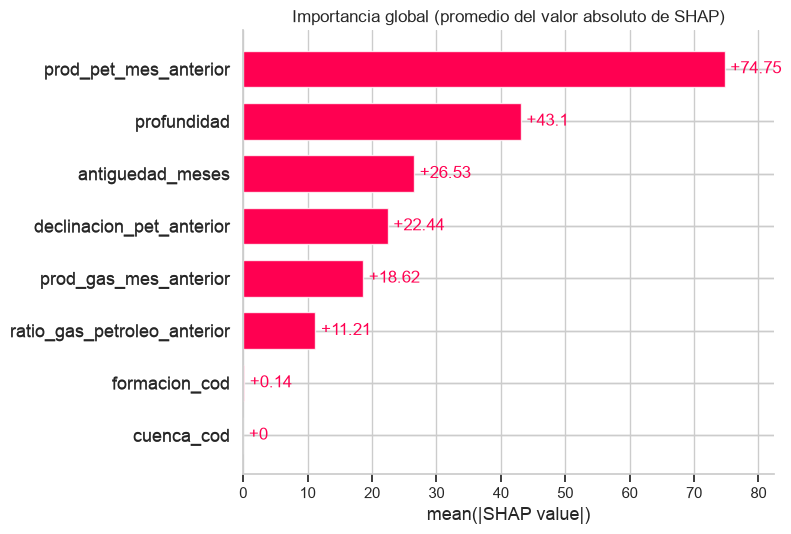

In [17]:
shap.plots.bar(shap_values, show=False)
plt.title("Importancia global (promedio del valor absoluto de SHAP)")
plt.tight_layout()
plt.savefig("reports/shap_importancia_global.png", dpi=150, bbox_inches="tight")
plt.show()

**Comparacion con la importancia de LightGBM:** la importancia por defecto cuenta cuantas
veces se uso cada variable para dividir un arbol, no cuanto mueve la prediccion. Comparamos
ambas medidas.

In [18]:
importancia_shap = pd.Series(np.abs(shap_values.values).mean(axis=0), index=columnas_features)
importancia_lgbm = pd.Series(modelo.feature_importances_, index=columnas_features)

comparacion_importancias = pd.DataFrame({
    "SHAP (promedio |valor|)": importancia_shap.round(1),
    "LightGBM (cantidad de splits)": importancia_lgbm,
}).sort_values("SHAP (promedio |valor|)", ascending=False)

comparacion_importancias

,SHAP (promedio |valor|),LightGBM (cantidad de splits)
prod_pet_mes_anterior,74.8,2073
profundidad,43.1,2195
antiguedad_meses,26.5,1566
declinacion_pet_anterior,22.4,1987
prod_gas_mes_anterior,18.6,1279
ratio_gas_petroleo_anterior,11.2,1748
formacion_cod,0.1,62
cuenca_cod,0.0,0


## Paso 5: Direccion del efecto de cada variable (beeswarm)

Cada punto es un pozo-mes. En el eje horizontal se ve cuanto sube (derecha) o baja (izquierda)
la variacion predicha, y el color indica si el valor de la variable era alto (rojo) o bajo
(azul).

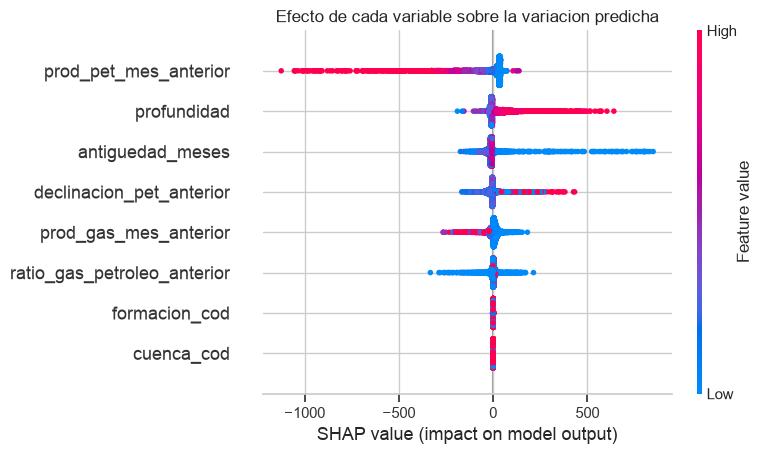

In [19]:
shap.plots.beeswarm(shap_values, show=False)
plt.title("Efecto de cada variable sobre la variacion predicha")
plt.tight_layout()
plt.savefig("reports/shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

## Paso 6: Como cambia el efecto segun el valor de la variable

Los graficos de dependencia muestran, para una variable, como cambia su contribucion a medida que
cambia su valor. Miramos las dos variables mas importantes segun el Paso 4.

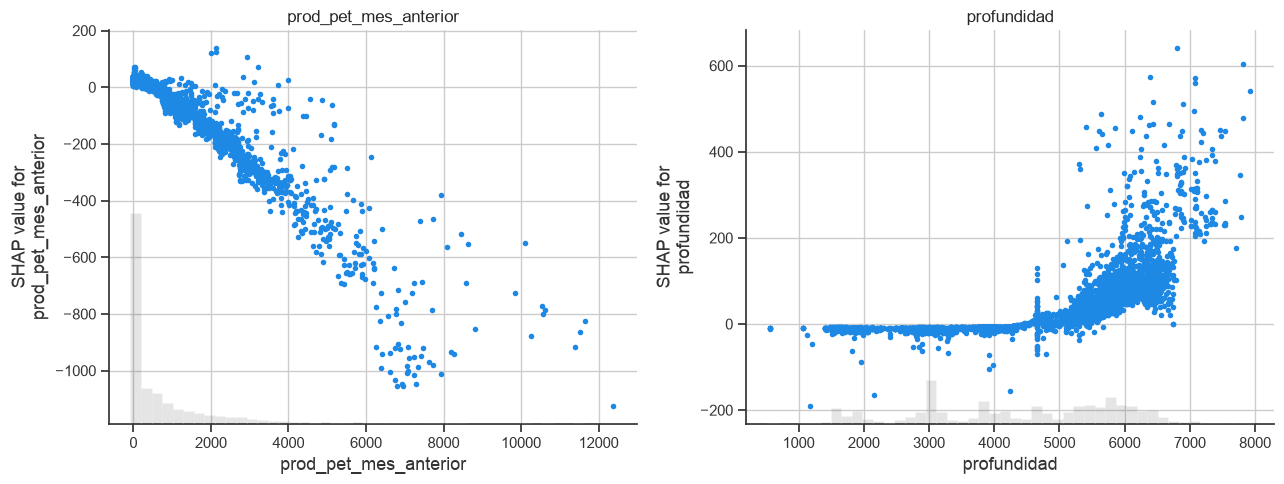

In [20]:
dos_principales = importancia_shap.sort_values(ascending=False).index[:2]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for eje, variable in zip(axes, dos_principales):
    shap.plots.scatter(shap_values[:, variable], ax=eje, show=False)
    eje.set_title(variable)

plt.tight_layout()
plt.savefig("reports/shap_dependencia.png", dpi=150, bbox_inches="tight")
plt.show()

## Paso 7: Explicar el caso mas problematico - pico alto subestimado

La limitacion conocida del modelo es que **subestima los pozos con picos muy altos (>10.000)**.
SHAP nos permite mirar un caso concreto: tomamos el mes de mayor error por subestimacion en esos
picos y vemos que variables empujaron la variacion predicha, para entender *por que* se quedo
corto.

In [21]:
# Meses de prueba con produccion real mayor a 10.000
mascara_picos = y_test > 10000
X_picos = X_test[mascara_picos]
y_picos = y_test[mascara_picos]
pred_picos = prediccion[mascara_picos]

print("Meses con produccion real > 10.000:", len(X_picos))

# Caso con la mayor subestimacion (real - predicho)
error_picos = y_picos - pred_picos
indice_peor = error_picos.idxmax()

print("Produccion real:         ", round(float(y_picos[indice_peor]), 1))
print("Produccion predicha:     ", round(float(pred_picos[indice_peor]), 1))
print("Produccion mes anterior: ", round(float(X_picos.loc[indice_peor, "prod_pet_mes_anterior"]), 1))
print("Pozo:", int(df.loc[indice_peor, "idpozo"]), "| Antiguedad (meses):", int(X_picos.loc[indice_peor, "antiguedad_meses"]))

Meses con produccion real > 10.000: 60
Produccion real:          24539.2
Produccion predicha:      10655.5
Produccion mes anterior:  12513.6
Pozo: 164941 | Antiguedad (meses): 12


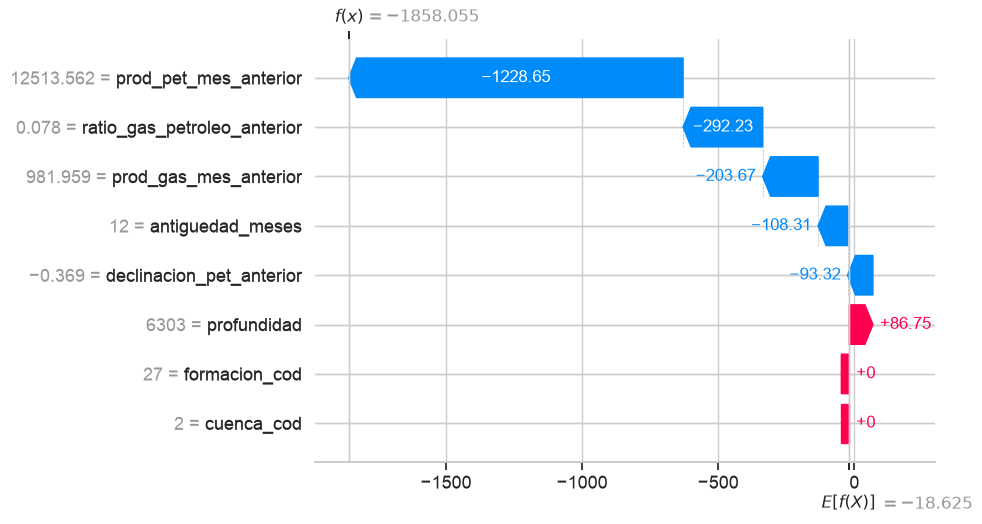

In [22]:
shap_peor = explainer(X_picos.loc[[indice_peor]])

plt.figure()  # figura nueva, para que no se mezcle con graficos anteriores
shap.plots.waterfall(shap_peor[0], show=False)
plt.savefig("reports/shap_caso_pico_subestimado.png", dpi=150, bbox_inches="tight")
plt.show()

**Como leer este grafico (waterfall):** parte de la variacion promedio (abajo) y suma o resta
la contribucion de cada variable hasta llegar a la variacion predicha para este mes (arriba). La
produccion predicha es el mes anterior mas esa variacion, y se compara con la produccion real
impresa arriba.

### Los picos altos en conjunto

Un solo caso puede ser una excepcion. Miramos entonces el patron en todos los meses de pico alto
del conjunto de prueba: el valor SHAP promedio de cada variable (con signo).

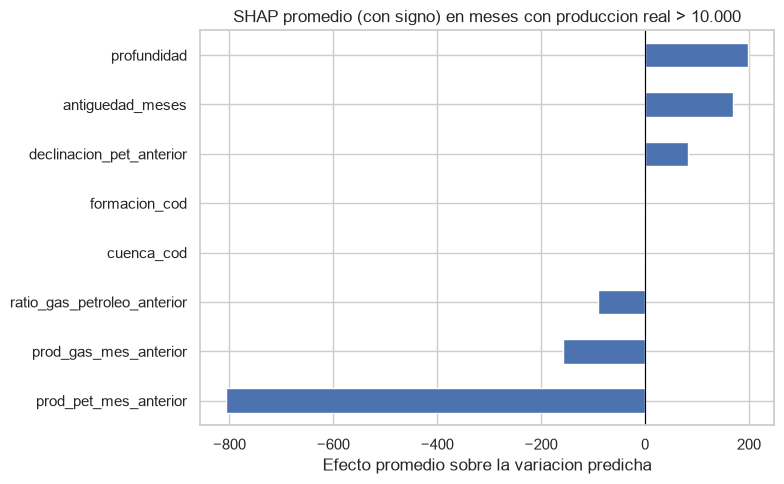

Variacion real promedio en picos:     1996.5
Variacion predicha promedio en picos: -622.6


In [23]:
shap_picos = explainer(X_picos)

shap_promedio_picos = pd.Series(
    shap_picos.values.mean(axis=0), index=columnas_features
).sort_values()

plt.figure(figsize=(8, 5))
shap_promedio_picos.plot(kind="barh", color="#4C72B0")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("SHAP promedio (con signo) en meses con produccion real > 10.000")
plt.xlabel("Efecto promedio sobre la variacion predicha")
plt.tight_layout()
plt.savefig("reports/shap_picos_altos.png", dpi=150, bbox_inches="tight")
plt.show()

variacion_real_picos = y_picos - X_picos["prod_pet_mes_anterior"]
print("Variacion real promedio en picos:    ", round(float(variacion_real_picos.mean()), 1))
print("Variacion predicha promedio en picos:", round(float((pred_picos - X_picos["prod_pet_mes_anterior"]).mean()), 1))

## Paso 8: Que tan raros eran los picos para el modelo

Los modelos de arboles (LightGBM, XGBoost) no pueden predecir por encima de lo que vieron al
entrenar: no extrapolan, solo reparten valores que ya conocen. Revisamos cuantos ejemplos de
produccion muy alta vio el modelo mientras entrenaba.

In [24]:
print("Maximo de prod_pet en entrenamiento (hasta 2023):", round(train["prod_pet"].max(), 1))
print("Maximo de prod_pet en prueba (2024-2025):        ", round(test["prod_pet"].max(), 1))
print()
print("Filas de entrenamiento con prod_pet > 10.000:", (train["prod_pet"] > 10000).sum(), "de", len(train))
print("Filas de prueba con prod_pet > 10.000:       ", (test["prod_pet"] > 10000).sum(), "de", len(test))

Maximo de prod_pet en entrenamiento (hasta 2023): 15942.5
Maximo de prod_pet en prueba (2024-2025):         26593.3

Filas de entrenamiento con prod_pet > 10.000: 36 de 170927
Filas de prueba con prod_pet > 10.000:        60 de 65574


## Conclusiones

- **Variable dominante:** prod_pet_mes_anterior (SHAP promedio de 75.1), seguida de profundidad (44.3) y
  antiguedad_meses (23.2). Cuanto mas produjo el pozo el mes anterior, mas baja la variacion
  predicha (hasta alrededor de -1.100 en los valores mas altos): el modelo aprendio que los pozos
  muy productivos tienden a declinar.
- **Direccion del efecto:** la antiguedad aporta sobre todo en los primeros meses de vida del pozo
  (suma hasta cerca de +800, el arranque de la produccion) y es casi neutra en los pozos viejos. Una
  declinacion previa alta suma (inercia), y un gas alto del mes anterior resta. La profundidad suma
  a partir de unos 5.000 m, probablemente porque los pozos profundos son los modernos de Vaca Muerta
  (es una asociacion, no una causa).
- **Importancia por splits contra SHAP:** la cantidad de splits sobrestima a las variables de poco
  efecto: `ratio_gas_petroleo_anterior` se usa 647 veces pero mueve en promedio 9.5,
  y `declinacion_pet_anterior` se usa 747 veces con 21.4.
- **Variables de poco aporte:** `formacion_cod` (1.07) y `cuenca_cod` (0.00) casi no mueven la
  prediccion; se podrian sacar del modelo sin perdida.
- **Picos altos:** en los 60 meses con produccion real mayor a 10.000 la variacion real promedio fue
  de 1996.5 y la predicha de -564.1: el modelo espera que un pozo muy productivo
  decline (prod_pet_mes_anterior aporta -827 en promedio), pero estos meses son justamente
  aquellos en que la produccion subio mucho. En el caso mas subestimado (pozo 164941) el mes anterior
  fue 12514, el modelo predijo 10827 y la produccion real fue 24539: un salto que estas
  variables no permiten anticipar.
- **Rango de entrenamiento:** el maximo visto al entrenar fue 15943 (solo 36 filas con mas
  de 10.000 sobre 170.927) y en prueba hay picos de hasta 26593. Los modelos de
  arboles no extrapolan, por lo que esto explica al menos en parte la subestimacion, ademas de la
  hipotesis de reestimulaciones del notebook 03.
- **Limitacion:** SHAP explica como usa el modelo las variables, no prueba causalidad: una variable
  importante para el modelo no es necesariamente la causa fisica de la produccion.

**Proximo paso:** entrega final (API con FastAPI, frontend de pruebas y Docker Compose).